# 05 — Candidate Model Evaluation

## Objective

This notebook compares three representative modelling approaches:

1. UCI-style Kernel Ridge as the reference baseline;
2. cost-sensitive Logistic Regression as an interpretable classifier;
3. XGBoost as a nonlinear tree-based model.

The models are evaluated using the same stratified 10-fold
cross-validation splits and out-of-fold predictions.

Threshold-independent metrics are used to compare risk-ranking ability.
Default-threshold metrics are used only to examine initial alarm
behaviour. Final model selection will be made after threshold analysis.

## 5.1 Setup

Import the libraries required for data processing, modelling, and
cross-validation.

In [25]:
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    roc_auc_score
)
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import xgboost as xgb
from xgboost import XGBClassifier

print("XGBoost version:", xgb.__version__)

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
XGBoost version: 3.4.1


## 5.2 Load the Data

The original labels are converted to binary labels:

- Pass (`-1`) becomes `0`;
- Fail (`+1`) becomes `1`.

Fail remains the positive class throughout this notebook.

In [3]:
data_dir = Path("../data/raw")

feature_path = data_dir / "secom.data"
label_path = data_dir / "secom_labels.data"

X = pd.read_csv(
    feature_path,
    sep=r"\s+",
    header=None,
    na_values="NaN"
)

X.columns = [
    f"feature_{i}"
    for i in range(X.shape[1])
]

labels_raw = pd.read_csv(
    label_path,
    sep=r"\s+",
    header=None
)

y_original = labels_raw.iloc[:, 0]
y = (y_original == 1).astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nBinary class counts:")
print(y.value_counts().sort_index())

assert len(X) == len(y)
assert set(y.unique()) == {0, 1}

X shape: (1567, 590)
y shape: (1567,)

Binary class counts:
0
0    1463
1     104
Name: count, dtype: int64


## 5.3 Cross-Validation Design

All candidate models use the same stratified 10-fold splits.

Stratification keeps approximately the same Pass/Fail proportion in
every validation fold. Using identical folds ensures that differences
between models are not caused by different data splits.

In [4]:
cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

In [5]:
fold_class_counts = []

for fold_number, (train_index, validation_index) in enumerate(
    cv.split(X, y),
    start=1
):
    y_validation = y.iloc[validation_index]

    fold_class_counts.append({
        "fold": fold_number,
        "validation_size": len(validation_index),
        "validation_pass": (y_validation == 0).sum(),
        "validation_fail": (y_validation == 1).sum()
    })

fold_class_counts = pd.DataFrame(fold_class_counts)
fold_class_counts

,fold,validation_size,validation_pass,validation_fail
0,1,157,147,10
1,2,157,147,10
2,3,157,147,10
3,4,157,146,11
4,5,157,146,11
5,6,157,146,11
6,7,157,146,11
7,8,156,146,10
8,9,156,146,10
9,10,156,146,10


### 5.4.1 UCI-style Kernel Ridge

Kernel Ridge is retained as the reference baseline from Chapter 4.

The pipeline performs median imputation, removes constant features,
standardizes the measurements, selects 40 features using the F-test,
and fits a linear Kernel Ridge model.

In [6]:
kernel_ridge_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "constant_removal",
        VarianceThreshold(threshold=0.0)
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "feature_selection",
        SelectKBest(
            score_func=f_classif,
            k=40
        )
    ),
    (
        "model",
        KernelRidge(
            alpha=1.0,
            kernel="linear"
        )
    )
])

### 5.4.2 Cost-sensitive Logistic Regression

Logistic Regression provides an interpretable probabilistic linear
classifier.

Balanced class weights increase the training importance of the
minority Fail class. The preprocessing structure remains comparable
with the UCI-style baseline.

In [8]:
logistic_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "constant_removal",
        VarianceThreshold(threshold=0.0)
    ),
    (
        "scaler",
        StandardScaler()
    ),
    (
        "feature_selection",
        SelectKBest(
            score_func=f_classif,
            k=40
        )
    ),
    (
        "model",
        LogisticRegression(
            l1_ratio=0.0,
            C=1.0,
            class_weight="balanced",
            solver="lbfgs",
            max_iter=5000
        )
    )
])

### 5.4.3 XGBoost with 40 F-test Features

The first XGBoost experiment uses the same 40 selected features as the
linear models. This provides a controlled comparison under a similar
feature set.

Scaling is not required because tree-based models split variables using
thresholds rather than distances.

In [9]:
xgb_40_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "constant_removal",
        VarianceThreshold(threshold=0.0)
    ),
    (
        "feature_selection",
        SelectKBest(
            score_func=f_classif,
            k=40
        )
    ),
    (
        "model",
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            min_child_weight=1,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.0,
            reg_lambda=1.0,
            scale_pos_weight=1.0,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )
    )
])

### 5.4.4 XGBoost with All Nonconstant Features

A second XGBoost configuration retains all nonconstant features.

This sensitivity experiment checks whether univariate F-test selection
removes variables that are weak individually but useful through
nonlinear relationships or feature interactions.

In [10]:
xgb_all_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "constant_removal",
        VarianceThreshold(threshold=0.0)
    ),
    (
        "model",
        XGBClassifier(
            objective="binary:logistic",
            eval_metric="logloss",
            n_estimators=200,
            learning_rate=0.05,
            max_depth=3,
            min_child_weight=1,
            subsample=0.8,
            colsample_bytree=0.8,
            reg_alpha=0.0,
            reg_lambda=1.0,
            scale_pos_weight=1.0,
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )
    )
])

### 5.4.5 Class-weighted Random Forest

Random Forest provides a bagging-based nonlinear comparison with
XGBoost.

Unlike boosting, Random Forest trains many partially independent trees
using bootstrap samples and random feature subsets, then combines their
predictions.

All nonconstant features are retained because the previous XGBoost
sensitivity experiment showed that F-test feature selection may remove
useful nonlinear or interaction information.

Class imbalance is addressed using balanced class weights rather than
synthetic oversampling.

In [26]:
random_forest_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "constant_removal",
        VarianceThreshold(threshold=0.0)
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=500,
            max_depth=6,
            min_samples_leaf=3,
            max_features="sqrt",
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        )
    )
])

random_forest_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('constant_removal', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimat

## 5.5 Reusable Evaluation Function

The same evaluation function is used for all candidate models.

For each fold, the function:

1. fits the complete pipeline using only the training fold;
2. generates continuous risk scores for the validation fold;
3. converts scores into class predictions using the initial threshold;
4. calculates fold-level metrics;
5. stores out-of-fold risk scores for every sample.

Kernel Ridge uses its continuous prediction score and a threshold of
zero. Logistic Regression and XGBoost use predicted Fail probabilities
and an initial threshold of 0.5.

In [11]:
def calculate_metrics(y_true, y_score, threshold):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)

    y_pred = (y_score >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    tpr = tp / (tp + fn)
    tnr = tn / (tn + fp)

    ber = (
        (1 - tpr) +
        (1 - tnr)
    ) / 2

    return {
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
        "predicted_fail": int(y_pred.sum()),
        "accuracy": accuracy_score(y_true, y_pred),
        "tpr": tpr,
        "tnr": tnr,
        "ber": ber,
        "precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "f1": f1_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "pr_auc": average_precision_score(
            y_true,
            y_score
        ),
        "roc_auc": roc_auc_score(
            y_true,
            y_score
        )
    }

In [12]:
def evaluate_model(
    model_name,
    pipeline,
    X,
    y,
    cv,
    score_method,
    threshold,
    signed_training_target=False,
    set_xgb_class_weight=False
):
    oof_scores = np.full(
        shape=len(y),
        fill_value=np.nan,
        dtype=float
    )

    fold_records = []

    for fold_number, (
        train_index,
        validation_index
    ) in enumerate(
        cv.split(X, y),
        start=1
    ):
        X_train = X.iloc[train_index]
        X_validation = X.iloc[validation_index]

        y_train = y.iloc[train_index].to_numpy()
        y_validation = y.iloc[validation_index].to_numpy()

        fitted_pipeline = clone(pipeline)

        if set_xgb_class_weight:
            n_pass_train = (y_train == 0).sum()
            n_fail_train = (y_train == 1).sum()

            scale_pos_weight = (
                n_pass_train / n_fail_train
            )

            fitted_pipeline.set_params(
                model__scale_pos_weight=scale_pos_weight
            )

        if signed_training_target:
            y_train_for_fit = np.where(
                y_train == 1,
                1,
                -1
            )
        else:
            y_train_for_fit = y_train

        fitted_pipeline.fit(
            X_train,
            y_train_for_fit
        )

        if score_method == "predict_proba":
            validation_scores = (
                fitted_pipeline
                .predict_proba(X_validation)[:, 1]
            )

        elif score_method == "predict":
            validation_scores = (
                fitted_pipeline
                .predict(X_validation)
            )

        else:
            raise ValueError(
                "score_method must be "
                "'predict_proba' or 'predict'."
            )

        oof_scores[validation_index] = validation_scores

        fold_metrics = calculate_metrics(
            y_true=y_validation,
            y_score=validation_scores,
            threshold=threshold
        )

        fold_metrics["fold"] = fold_number
        fold_records.append(fold_metrics)

        print(
            f"{model_name}: "
            f"fold {fold_number}/10 complete"
        )

    assert not np.isnan(oof_scores).any()

    fold_results = pd.DataFrame(fold_records)

    pooled_metrics = calculate_metrics(
        y_true=y,
        y_score=oof_scores,
        threshold=threshold
    )

    return {
        "model": model_name,
        "threshold": threshold,
        "oof_scores": oof_scores,
        "fold_results": fold_results,
        "pooled_metrics": pooled_metrics
    }

## 5.6 Generate Out-of-Fold Risk Scores

The following experiments use identical cross-validation folds.

The two XGBoost configurations form a feature-set sensitivity analysis,
not two fundamentally different model families.

In [13]:
kernel_ridge_result = evaluate_model(
    model_name="Kernel Ridge",
    pipeline=kernel_ridge_pipeline,
    X=X,
    y=y,
    cv=cv,
    score_method="predict",
    threshold=0.0,
    signed_training_target=True,
    set_xgb_class_weight=False
)

Kernel Ridge: fold 1/10 complete
Kernel Ridge: fold 2/10 complete
Kernel Ridge: fold 3/10 complete
Kernel Ridge: fold 4/10 complete
Kernel Ridge: fold 5/10 complete
Kernel Ridge: fold 6/10 complete
Kernel Ridge: fold 7/10 complete
Kernel Ridge: fold 8/10 complete
Kernel Ridge: fold 9/10 complete
Kernel Ridge: fold 10/10 complete


In [14]:
logistic_result = evaluate_model(
    model_name="Logistic Regression",
    pipeline=logistic_pipeline,
    X=X,
    y=y,
    cv=cv,
    score_method="predict_proba",
    threshold=0.5,
    signed_training_target=False,
    set_xgb_class_weight=False
)

Logistic Regression: fold 1/10 complete
Logistic Regression: fold 2/10 complete
Logistic Regression: fold 3/10 complete
Logistic Regression: fold 4/10 complete
Logistic Regression: fold 5/10 complete
Logistic Regression: fold 6/10 complete
Logistic Regression: fold 7/10 complete
Logistic Regression: fold 8/10 complete
Logistic Regression: fold 9/10 complete
Logistic Regression: fold 10/10 complete


In [15]:
xgb_40_result = evaluate_model(
    model_name="XGBoost — Top 40",
    pipeline=xgb_40_pipeline,
    X=X,
    y=y,
    cv=cv,
    score_method="predict_proba",
    threshold=0.5,
    signed_training_target=False,
    set_xgb_class_weight=True
)

XGBoost — Top 40: fold 1/10 complete
XGBoost — Top 40: fold 2/10 complete
XGBoost — Top 40: fold 3/10 complete
XGBoost — Top 40: fold 4/10 complete
XGBoost — Top 40: fold 5/10 complete
XGBoost — Top 40: fold 6/10 complete
XGBoost — Top 40: fold 7/10 complete
XGBoost — Top 40: fold 8/10 complete
XGBoost — Top 40: fold 9/10 complete
XGBoost — Top 40: fold 10/10 complete


In [16]:
xgb_all_result = evaluate_model(
    model_name="XGBoost — All Features",
    pipeline=xgb_all_pipeline,
    X=X,
    y=y,
    cv=cv,
    score_method="predict_proba",
    threshold=0.5,
    signed_training_target=False,
    set_xgb_class_weight=True
)

XGBoost — All Features: fold 1/10 complete
XGBoost — All Features: fold 2/10 complete
XGBoost — All Features: fold 3/10 complete
XGBoost — All Features: fold 4/10 complete
XGBoost — All Features: fold 5/10 complete
XGBoost — All Features: fold 6/10 complete
XGBoost — All Features: fold 7/10 complete
XGBoost — All Features: fold 8/10 complete
XGBoost — All Features: fold 9/10 complete
XGBoost — All Features: fold 10/10 complete


### 5.6.5 Random Forest Evaluation

The Random Forest pipeline is evaluated using the same stratified
10-fold splits and the same reusable evaluation function.

Its out-of-fold Fail scores are generated using `predict_proba`.
The initial probability threshold is 0.5.

In [27]:
random_forest_result = evaluate_model(
    model_name="Random Forest",
    pipeline=random_forest_pipeline,
    X=X,
    y=y,
    cv=cv,
    score_method="predict_proba",
    threshold=0.5,
    signed_training_target=False,
    set_xgb_class_weight=False
)

Random Forest: fold 1/10 complete
Random Forest: fold 2/10 complete
Random Forest: fold 3/10 complete
Random Forest: fold 4/10 complete
Random Forest: fold 5/10 complete
Random Forest: fold 6/10 complete
Random Forest: fold 7/10 complete
Random Forest: fold 8/10 complete
Random Forest: fold 9/10 complete
Random Forest: fold 10/10 complete


## 5.7 Threshold-independent Comparison

PR-AUC and ROC-AUC evaluate the ordering of the continuous risk scores
without relying on one fixed decision threshold.

Because Fail samples represent only a small proportion of the dataset,
PR-AUC is treated as the primary ranking metric. The Fail prevalence is
included as a no-skill reference level.

In [28]:
all_results = {
    "Kernel Ridge": kernel_ridge_result,
    "Logistic Regression": logistic_result,
    "XGBoost — Top 40": xgb_40_result,
    "XGBoost — All Features": xgb_all_result,
    "Random Forest": random_forest_result
}

fail_prevalence = y.mean()

ranking_rows = []

for model_name, result in all_results.items():
    pooled = result["pooled_metrics"]

    ranking_rows.append({
        "model": model_name,
        "pr_auc": pooled["pr_auc"],
        "roc_auc": pooled["roc_auc"],
        "pr_auc_lift_over_prevalence": (
            pooled["pr_auc"] / fail_prevalence
        )
    })

ranking_comparison = (
    pd.DataFrame(ranking_rows)
    .set_index("model")
    .sort_values(
        by="pr_auc",
        ascending=False
    )
)

print(
    "Fail prevalence:",
    round(fail_prevalence, 4)
)

(ranking_comparison * 100).round(2)

Fail prevalence: 0.0664


,pr_auc,roc_auc,pr_auc_lift_over_prevalence
model,,,
XGBoost — All Features,17.81,72.65,268.39
Random Forest,16.27,74.57,245.15
Logistic Regression,15.94,71.92,240.15
Kernel Ridge,15.78,72.53,237.78
XGBoost — Top 40,14.48,73.32,218.19


In [30]:
ranking_display = ranking_comparison.copy()

ranking_display["pr_auc"] *= 100
ranking_display["roc_auc"] *= 100

ranking_display.columns = [
    "average_precision_percent",
    "roc_auc_percent",
    "ap_lift"
]

ranking_display.round(2)

,average_precision_percent,roc_auc_percent,ap_lift
model,,,
XGBoost — All Features,17.81,72.65,2.68
Random Forest,16.27,74.57,2.45
Logistic Regression,15.94,71.92,2.40
Kernel Ridge,15.78,72.53,2.38
XGBoost — Top 40,14.48,73.32,2.18


## 5.8 Default-threshold Diagnostic

This table describes the initial alarm behaviour of each model.

Kernel Ridge uses a score threshold of zero. Logistic Regression and
XGBoost use a probability threshold of 0.5.

These results are diagnostic operating points rather than the final
basis for model selection.

In [31]:
default_threshold_rows = []

for model_name, result in all_results.items():
    pooled = result["pooled_metrics"]

    default_threshold_rows.append({
        "model": model_name,
        "threshold": result["threshold"],
        "predicted_fail": pooled["predicted_fail"],
        "tp": pooled["tp"],
        "fn": pooled["fn"],
        "fp": pooled["fp"],
        "tn": pooled["tn"],
        "tpr": pooled["tpr"],
        "tnr": pooled["tnr"],
        "ber": pooled["ber"],
        "precision": pooled["precision"],
        "f1": pooled["f1"]
    })

default_threshold_comparison = (
    pd.DataFrame(default_threshold_rows)
    .set_index("model")
)

default_threshold_comparison

,threshold,predicted_fail,tp,fn,fp,tn,tpr,tnr,ber,precision,f1
model,,,,,,,,,,,
Kernel Ridge,0.0,665,76,28,589,874,0.730769,0.597403,0.335914,0.114286,0.197659
Logistic Regression,0.5,419,61,43,358,1105,0.586538,0.755297,0.329082,0.145585,0.233270
XGBoost — Top 40,0.5,167,24,80,143,1320,0.230769,0.902256,0.433488,0.143713,0.177122
XGBoost — All Features,0.5,49,16,88,33,1430,0.153846,0.977444,0.434355,0.326531,0.209150
Random Forest,0.5,0,0,104,0,1463,0.000000,1.000000,0.500000,0.000000,0.000000


In [32]:
default_percent = (
    default_threshold_comparison[
        [
            "tpr",
            "tnr",
            "ber",
            "precision",
            "f1"
        ]
    ] * 100
).round(2)

default_percent

,tpr,tnr,ber,precision,f1
model,,,,,
Kernel Ridge,73.08,59.74,33.59,11.43,19.77
Logistic Regression,58.65,75.53,32.91,14.56,23.33
XGBoost — Top 40,23.08,90.23,43.35,14.37,17.71
XGBoost — All Features,15.38,97.74,43.44,32.65,20.92
Random Forest,0.00,100.00,50.00,0.00,0.00


## 5.9 Cross-validation Stability

The standard deviation across folds measures how strongly model
performance changes with the validation sample.

Large variation in Fail recall is expected because each validation fold
contains only approximately 10 or 11 Fail samples.

In [33]:
stability_rows = []

stability_metrics = [
    "accuracy",
    "tpr",
    "tnr",
    "ber",
    "precision",
    "f1",
    "pr_auc",
    "roc_auc"
]

for model_name, result in all_results.items():
    fold_std = (
        result["fold_results"][stability_metrics]
        .std()
    )

    row = {
        "model": model_name
    }

    for metric in stability_metrics:
        row[metric] = fold_std[metric]

    stability_rows.append(row)

stability_comparison = (
    pd.DataFrame(stability_rows)
    .set_index("model")
)

(stability_comparison * 100).round(2)

,accuracy,tpr,tnr,ber,precision,f1,pr_auc,roc_auc
model,,,,,,,,
Kernel Ridge,4.98,14.53,5.10,7.98,2.72,4.49,4.06,8.79
Logistic Regression,5.22,16.03,5.55,8.32,4.42,6.72,3.21,7.19
XGBoost — Top 40,2.53,11.68,2.91,5.44,7.26,8.55,6.78,5.95
XGBoost — All Features,1.09,8.42,1.02,4.19,16.97,10.66,6.56,4.50
Random Forest,0.32,0.00,0.00,0.00,0.00,0.00,9.27,6.29


## 5.10 Prepare Out-of-Fold Scores for Threshold Analysis

The out-of-fold scores from the candidate models are combined into one
table for threshold analysis.

Each score was generated by a model that did not train on that sample.
This reduces the optimistic bias that would occur if thresholds were
examined using in-sample predictions.

The scores are also saved to support reproducibility and later analysis.

In [38]:
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

oof_scores = pd.DataFrame({
    "label": y.to_numpy(),

    "kernel_ridge_score": (
        kernel_ridge_result["oof_scores"]
    ),

    "logistic_risk_score": (
        logistic_result["oof_scores"]
    ),

    "xgb_all_risk_score": (
        xgb_all_result["oof_scores"]
    ),

    "random_forest_risk_score": (
        random_forest_result["oof_scores"]
    )
})

oof_path = output_dir / "chapter5_oof_scores.csv"
oof_scores.to_csv(oof_path, index=False)

print("Saved to:", oof_path)
print("Saved shape:", oof_scores.shape)

oof_scores.head()

Saved to: ../data/processed/chapter5_oof_scores.csv
Saved shape: (1567, 5)


,label,kernel_ridge_score,logistic_risk_score,xgb_all_risk_score,random_forest_risk_score
0,0,0.078874,0.585929,0.108223,0.287267
1,0,0.058199,0.567115,0.178062,0.243421
2,1,0.338568,0.874056,0.231234,0.320069
3,0,2.377568,0.975337,0.171437,0.284752
4,0,0.128372,0.439304,0.125794,0.306376


In [35]:
ranking_path = (
    output_dir /
    "chapter5_ranking_metrics.csv"
)

default_threshold_path = (
    output_dir /
    "chapter5_default_threshold_metrics.csv"
)

stability_path = (
    output_dir /
    "chapter5_stability_metrics.csv"
)

ranking_comparison.to_csv(ranking_path)

default_threshold_comparison.to_csv(
    default_threshold_path
)

stability_comparison.to_csv(stability_path)

print("Saved files:")
print("-", ranking_path)
print("-", default_threshold_path)
print("-", stability_path)

Saved files:
- ../data/processed/chapter5_ranking_metrics.csv
- ../data/processed/chapter5_default_threshold_metrics.csv
- ../data/processed/chapter5_stability_metrics.csv


## 5.11 Random Forest Score Diagnostic

The default threshold of 0.5 produced no Fail predictions for the
Random Forest. Therefore, the distribution of its out-of-fold risk
scores is examined before threshold selection.

This diagnostic checks:

1. why the default threshold produced no Fail alarms;
2. whether actual Fail samples still receive higher risk scores than
   actual Pass samples.

A default threshold failure does not necessarily mean that the model
has no ranking ability.

In [39]:
random_forest_score_summary = (
    pd.Series(
        random_forest_result["oof_scores"],
        name="random_forest_risk_score"
    )
    .describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

random_forest_score_summary

count    1567.000000
mean        0.206771
std         0.075939
min         0.063447
50%         0.194022
75%         0.250333
90%         0.314708
95%         0.354084
99%         0.422972
max         0.470654
Name: random_forest_risk_score, dtype: float64

In [40]:
random_forest_score_by_class = pd.DataFrame({
    "label": y.to_numpy(),
    "risk_score": random_forest_result["oof_scores"]
})

random_forest_score_by_class.groupby(
    "label"
)["risk_score"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,1463.0,0.202237,0.073658,0.063447,0.150138,0.191218,0.244615,0.470654
1,104.0,0.270554,0.079169,0.075275,0.215260,0.268577,0.320890,0.456670


### Observation

The maximum Random Forest OOF risk score is below 0.5, which explains
why the default threshold classified every sample as Pass.

However, actual Fail samples receive higher mean and median risk scores
than actual Pass samples. This indicates that the model contains useful
ranking information, although the two score distributions overlap.

Therefore, the Random Forest should not be rejected solely because of
its performance at the default threshold. Its operating threshold
should be evaluated together with the other candidate models.

## 5.12 Threshold Evaluation Function

A threshold converts a continuous risk score into a Pass/Fail decision.

For each threshold, the following quantities are calculated:

- Fail recall (TPR);
- Pass specificity (TNR);
- Balanced Error Rate (BER);
- precision;
- F1 score;
- alarm rate;
- false alarms per detected Fail.

The same function is applied to every candidate model so that their
operating points can be compared consistently.

In [41]:
from sklearn.metrics import confusion_matrix


def calculate_threshold_metrics(
    y_true,
    risk_scores,
    threshold
):
    y_true = np.asarray(y_true)
    risk_scores = np.asarray(risk_scores)

    y_pred = (
        risk_scores >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    tpr = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else 0
    )

    tnr = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else 0
    )

    f1 = (
        2 * precision * tpr / (precision + tpr)
        if (precision + tpr) > 0
        else 0
    )

    ber = (
        (1 - tpr) +
        (1 - tnr)
    ) / 2

    predicted_fail = tp + fp
    alarm_rate = predicted_fail / len(y_true)

    false_alarms_per_detected_fail = (
        fp / tp
        if tp > 0
        else np.inf
    )

    return {
        "threshold": threshold,
        "predicted_fail": predicted_fail,
        "alarm_rate": alarm_rate,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
        "tpr": tpr,
        "tnr": tnr,
        "ber": ber,
        "precision": precision,
        "f1": f1,
        "false_alarms_per_detected_fail": (
            false_alarms_per_detected_fail
        )
    }

## 5.13 Generate Threshold Trade-off Tables

Threshold analysis is performed for the four main candidate models:

- Kernel Ridge;
- Logistic Regression;
- XGBoost using all non-constant features;
- Random Forest.

XGBoost Top 40 is retained as a feature-set sensitivity experiment but
is not treated as a main candidate because its Average Precision is
lower than the all-feature XGBoost model.

In [42]:
candidate_scores = {
    "Kernel Ridge": (
        kernel_ridge_result["oof_scores"]
    ),

    "Logistic Regression": (
        logistic_result["oof_scores"]
    ),

    "XGBoost — All Features": (
        xgb_all_result["oof_scores"]
    ),

    "Random Forest": (
        random_forest_result["oof_scores"]
    )
}

In [43]:
threshold_tables = {}

for model_name, risk_scores in candidate_scores.items():

    candidate_thresholds = np.sort(
        np.unique(risk_scores)
    )

    threshold_rows = [
        calculate_threshold_metrics(
            y_true=y.to_numpy(),
            risk_scores=risk_scores,
            threshold=threshold
        )
        for threshold in candidate_thresholds
    ]

    threshold_tables[model_name] = (
        pd.DataFrame(threshold_rows)
    )

print(
    "Threshold tables created for:",
    list(threshold_tables.keys())
)

Threshold tables created for: ['Kernel Ridge', 'Logistic Regression', 'XGBoost — All Features', 'Random Forest']


## 5.14 Minimum-BER Operating Points

For each model, the threshold with the lowest Balanced Error Rate is
identified.

This operating point gives equal importance to the Fail error rate and
the Pass error rate. It is used as a statistical reference rather than
as a final production threshold.

In [44]:
minimum_ber_rows = []

for model_name, threshold_table in threshold_tables.items():

    best_row = (
        threshold_table
        .sort_values(
            by=[
                "ber",
                "predicted_fail"
            ],
            ascending=[
                True,
                True
            ]
        )
        .iloc[0]
        .copy()
    )

    best_row["model"] = model_name
    minimum_ber_rows.append(best_row)

minimum_ber_comparison = (
    pd.DataFrame(minimum_ber_rows)
    .set_index("model")
)

minimum_ber_comparison[
    [
        "threshold",
        "predicted_fail",
        "alarm_rate",
        "tp",
        "fn",
        "fp",
        "tn",
        "tpr",
        "tnr",
        "ber",
        "precision",
        "f1",
        "false_alarms_per_detected_fail"
    ]
].round(4)

,threshold,predicted_fail,alarm_rate,tp,fn,fp,tn,tpr,tnr,ber,precision,f1,false_alarms_per_detected_fail
model,,,,,,,,,,,,,
Kernel Ridge,0.0357,500.0,0.3191,70.0,34.0,430.0,1033.0,0.6731,0.7061,0.3104,0.1400,0.2318,6.1429
Logistic Regression,0.4550,484.0,0.3089,67.0,37.0,417.0,1046.0,0.6442,0.7150,0.3204,0.1384,0.2279,6.2239
XGBoost — All Features,0.1111,528.0,0.3369,70.0,34.0,458.0,1005.0,0.6731,0.6869,0.3200,0.1326,0.2215,6.5429
Random Forest,0.2146,614.0,0.3918,79.0,25.0,535.0,928.0,0.7596,0.6343,0.3030,0.1287,0.2201,6.7722


In [45]:
minimum_ber_display = minimum_ber_comparison[
    [
        "threshold",
        "predicted_fail",
        "alarm_rate",
        "tpr",
        "tnr",
        "ber",
        "precision",
        "f1",
        "false_alarms_per_detected_fail"
    ]
].copy()

percentage_columns = [
    "alarm_rate",
    "tpr",
    "tnr",
    "ber",
    "precision",
    "f1"
]

minimum_ber_display[
    percentage_columns
] *= 100

minimum_ber_display.round(2)

,threshold,predicted_fail,alarm_rate,tpr,tnr,ber,precision,f1,false_alarms_per_detected_fail
model,,,,,,,,,
Kernel Ridge,0.04,500.0,31.91,67.31,70.61,31.04,14.00,23.18,6.14
Logistic Regression,0.45,484.0,30.89,64.42,71.50,32.04,13.84,22.79,6.22
XGBoost — All Features,0.11,528.0,33.69,67.31,68.69,32.00,13.26,22.15,6.54
Random Forest,0.21,614.0,39.18,75.96,63.43,30.30,12.87,22.01,6.77


## 5.15 Recall-Constrained Operating Scenarios

In manufacturing monitoring, missing a true failure may be more costly
than inspecting an additional normal sample.

Therefore, hypothetical operating scenarios are examined at minimum
Fail recall requirements of 60%, 70%, and 80%.

For each requirement, the threshold with the highest Pass specificity
is selected among all thresholds that satisfy the recall constraint.

These recall targets are analytical scenarios, not actual fab
requirements.

In [46]:
recall_targets = [
    0.60,
    0.70,
    0.80
]

recall_scenario_rows = []

for model_name, threshold_table in threshold_tables.items():

    for target_recall in recall_targets:

        eligible_thresholds = threshold_table[
            threshold_table["tpr"] >= target_recall
        ]

        if eligible_thresholds.empty:
            continue

        selected_row = (
            eligible_thresholds
            .sort_values(
                by=[
                    "tnr",
                    "precision"
                ],
                ascending=[
                    False,
                    False
                ]
            )
            .iloc[0]
            .copy()
        )

        selected_row["model"] = model_name
        selected_row["required_recall"] = (
            target_recall
        )

        recall_scenario_rows.append(
            selected_row
        )

recall_scenarios = pd.DataFrame(
    recall_scenario_rows
)

In [47]:
recall_scenario_display = recall_scenarios[
    [
        "model",
        "required_recall",
        "threshold",
        "predicted_fail",
        "alarm_rate",
        "tp",
        "fn",
        "fp",
        "tn",
        "tpr",
        "tnr",
        "ber",
        "precision",
        "false_alarms_per_detected_fail"
    ]
].copy()

percentage_columns = [
    "required_recall",
    "alarm_rate",
    "tpr",
    "tnr",
    "ber",
    "precision"
]

recall_scenario_display[
    percentage_columns
] *= 100

recall_scenario_display.round(2)

,model,required_recall,threshold,predicted_fail,alarm_rate,tp,fn,fp,tn,tpr,tnr,ber,precision,false_alarms_per_detected_fail
1140,Kernel Ridge,60.0,0.06,427.0,27.25,63.0,41.0,364.0,1099.0,60.58,75.12,32.15,14.75,5.78
1014,Kernel Ridge,70.0,0.03,553.0,35.29,73.0,31.0,480.0,983.0,70.19,67.19,31.31,13.20,6.58
663,Kernel Ridge,80.0,-0.05,904.0,57.69,84.0,20.0,820.0,643.0,80.77,43.95,37.64,9.29,9.76
1128,Logistic Regression,60.0,0.49,439.0,28.02,63.0,41.0,376.0,1087.0,60.58,74.30,32.56,14.35,5.97
948,Logistic Regression,70.0,0.38,619.0,39.50,73.0,31.0,546.0,917.0,70.19,62.68,33.56,11.79,7.48
702,Logistic Regression,80.0,0.27,865.0,55.20,84.0,20.0,781.0,682.0,80.77,46.62,36.31,9.71,9.30
1125,XGBoost — All Features,60.0,0.14,442.0,28.21,63.0,41.0,379.0,1084.0,60.58,74.09,32.66,14.25,6.02
966,XGBoost — All Features,70.0,0.09,601.0,38.35,73.0,31.0,528.0,935.0,70.19,63.91,32.95,12.15,7.23
757,XGBoost — All Features,80.0,0.06,810.0,51.69,84.0,20.0,726.0,737.0,80.77,50.38,34.43,10.37,8.64
1159,Random Forest,60.0,0.25,408.0,26.04,63.0,41.0,345.0,1118.0,60.58,76.42,31.50,15.44,5.48


## 5.16 Threshold Trade-off Curves

The curves show how Fail recall, Pass specificity, and Balanced Error
Rate change as the decision threshold changes.

Each model is plotted separately because the score scales are not
directly comparable across models.

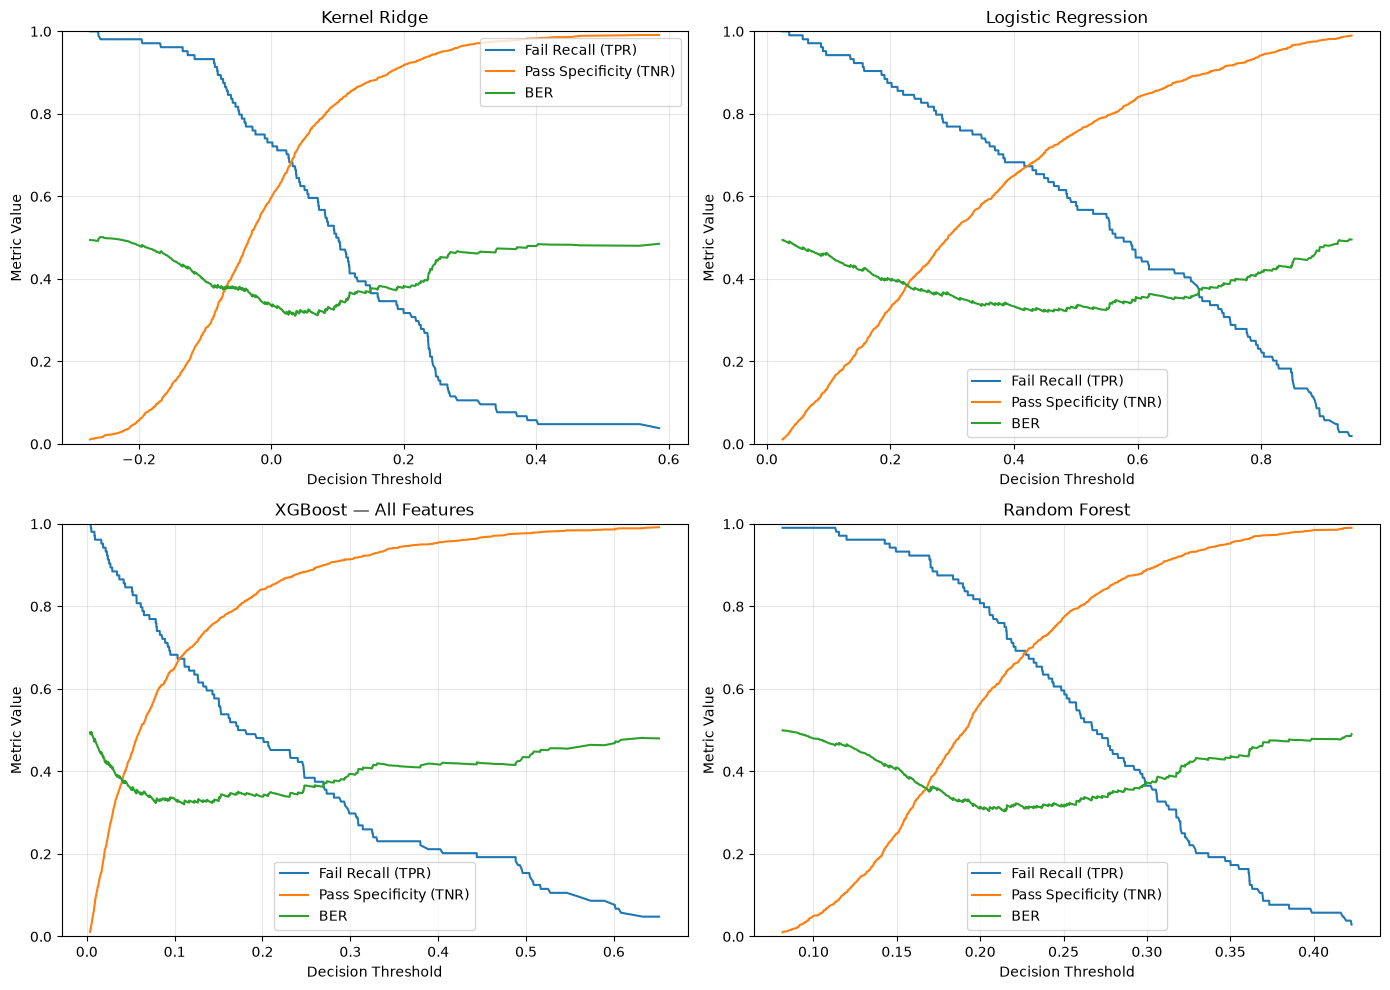

In [50]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(14, 10)
)

axes = axes.flatten()

for axis, (
    model_name,
    threshold_table
) in zip(
    axes,
    threshold_tables.items()
):

    lower_limit = threshold_table[
        "threshold"
    ].quantile(0.01)

    upper_limit = threshold_table[
        "threshold"
    ].quantile(0.99)

    plot_table = threshold_table[
        threshold_table["threshold"].between(
            lower_limit,
            upper_limit
        )
    ]

    axis.plot(
        plot_table["threshold"],
        plot_table["tpr"],
        label="Fail Recall (TPR)"
    )

    axis.plot(
        plot_table["threshold"],
        plot_table["tnr"],
        label="Pass Specificity (TNR)"
    )

    axis.plot(
        plot_table["threshold"],
        plot_table["ber"],
        label="BER"
    )

    axis.set_title(model_name)
    axis.set_xlabel("Decision Threshold")
    axis.set_ylabel("Metric Value")
    axis.set_ylim(0, 1)
    axis.grid(alpha=0.3)
    axis.legend()

plt.tight_layout()
plt.show()

## 5.17 Save Threshold Analysis Results

The threshold tables and selected operating scenarios are saved to
support reproducibility and later engineering interpretation.

In [49]:
minimum_ber_comparison.to_csv(
    output_dir /
    "chapter5_minimum_ber_operating_points.csv"
)

recall_scenarios.to_csv(
    output_dir /
    "chapter5_recall_scenarios.csv",
    index=False
)

for model_name, threshold_table in threshold_tables.items():

    safe_model_name = (
        model_name
        .lower()
        .replace(" ", "_")
        .replace("—", "")
        .replace("-", "_")
    )

    threshold_table.to_csv(
        output_dir /
        f"chapter5_thresholds_{safe_model_name}.csv",
        index=False
    )

print("Threshold analysis results saved.")

Threshold analysis results saved.


## 5.18 Chapter Summary

The candidate models were first compared using out-of-fold continuous
risk scores. This separated ranking performance from the later
threshold-based decision process.

XGBoost using all non-constant features achieved the highest Average
Precision, while Random Forest achieved the highest ROC-AUC. However,
the differences between the candidate models were modest.

The default threshold of 0.5 was not appropriate for every model. In
particular, all Random Forest OOF risk scores were below 0.5, although
actual Fail samples received higher scores on average than actual Pass
samples. This demonstrated that useful ranking information can exist
even when a default threshold produces no Fail predictions.

Under the minimum-BER analysis, Random Forest obtained the lowest BER
and the highest Fail recall, but required a high alarm rate. In the
recall-constrained analysis, Random Forest provided the strongest
trade-off at the 60% and 80% recall requirements, while Kernel Ridge
was slightly better at approximately 70% recall.

The results demonstrate that threshold selection is an engineering
decision rather than a purely statistical decision. Increasing Fail
recall requires accepting more false alarms and additional inspection
work.

Because the dataset does not provide the economic costs of missed
failures and false alarms, no single threshold can be claimed as the
production-optimal threshold. The reported thresholds should therefore
be interpreted as exploratory candidate operating points.

### Threshold-Selection Limitation

The thresholds were selected and evaluated using the same pooled
out-of-fold predictions. Although each OOF score was generated without
training on that sample, searching for the best threshold on the same
OOF results may still produce optimistic performance estimates.

A production study should validate the selected threshold using an
independent time period or nested cross-validation.

Random Forest was selected as the primary model for the downstream
investigation prototype. Its OOF Average Precision was only modestly
higher than that of Logistic Regression, so the selection should not be
interpreted as overwhelming predictive superiority.

The model was selected because it combined useful risk ranking with the
ability to represent nonlinear relationships and interactions, and it
supported validation-fold permutation importance for the subsequent
signal-stability analysis.